# Visualisation du corpus OCR

Ce notebook inspecte les manifests du Bulletin officiel : tailles d'images, longueurs des transcriptions, fréquence des caractères et exemples visuels. Il ne modifie pas les données.

In [1]:
from pathlib import Path
import json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

def locate_project():
    candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path.cwd().parent.parent.parent]
    for root in candidates:
        if (root / 'outputs' / 'arabic_ocr').is_dir() and (root / 'work' / 'data' / 'gazette').is_dir():
            return root
    raise FileNotFoundError('Projet introuvable : lancez Jupyter depuis le projet ou outputs/arabic_ocr.')

PROJECT = locate_project()
DATA = PROJECT / 'work' / 'data' / 'gazette'
print('Projet :', PROJECT)
print('Données :', DATA)

Projet : C:\Users\sail_\Documents\Codex\2026-10-29\oui-il-existe-des-datasets-adapt
Données : C:\Users\sail_\Documents\Codex\2026-10-29\oui-il-existe-des-datasets-adapt\work\data\gazette


In [2]:
def read_manifest(name):
    path = DATA / f'{name}.jsonl'
    rows = [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]
    for row in rows:
        row['split'] = name
        row['text_length'] = len(row['text'])
        row['word_count'] = len(row['text'].split())
    return rows

rows = sum((read_manifest(split) for split in ('train', 'val', 'test')), [])
df = pd.DataFrame(rows)
df.groupby('split').agg(samples=('id','size'), mean_chars=('text_length','mean'), median_chars=('text_length','median'), mean_words=('word_count','mean'))

,samples,mean_chars,median_chars,mean_words
split,,,,
test,1212,72.452145,84.0,11.943894
train,10357,68.213962,75.0,11.169258
val,1160,70.629310,78.5,11.639655


In [3]:
# Mesurer les dimensions originales des images. Cette cellule peut prendre quelques secondes.
sizes = []
for path in df['image']:
    with Image.open(path) as image:
        sizes.append((image.width, image.height, image.mode))
df[['width_px', 'height_px', 'mode']] = pd.DataFrame(sizes, index=df.index)
df.groupby('split')[['width_px','height_px','text_length']].describe().round(1)

width_px                                                     height_px  \
         count   mean    std    min    25%     50%     75%     max     count   
split                                                                          
test    1212.0  826.0  339.8  139.0  525.8   970.0  1091.0  1303.0    1212.0   
train  10357.0  907.3  342.5   43.0  613.0  1037.0  1203.0  1488.0   10357.0   
val     1160.0  908.3  338.5  112.0  631.8  1029.0  1202.2  1385.0    1160.0   

             ...              text_length                                      \
       mean  ...   75%    max       count  mean   std   min   25%   50%   75%   
split        ...                                                                
test   46.4  ...  54.0  144.0      1212.0  72.5  29.8  11.0  45.0  84.0  96.0   
train  49.8  ...  55.0  132.0     10357.0  68.2  26.9   1.0  46.0  75.0  90.0   
val    49.4  ...  54.0  105.0      1160.0  70.6  27.1   8.0  47.0  78.5  92.0   

              
         max  
split         
test   125.0  
train  134.0  
val    130.0  

[3 rows x 24 columns]

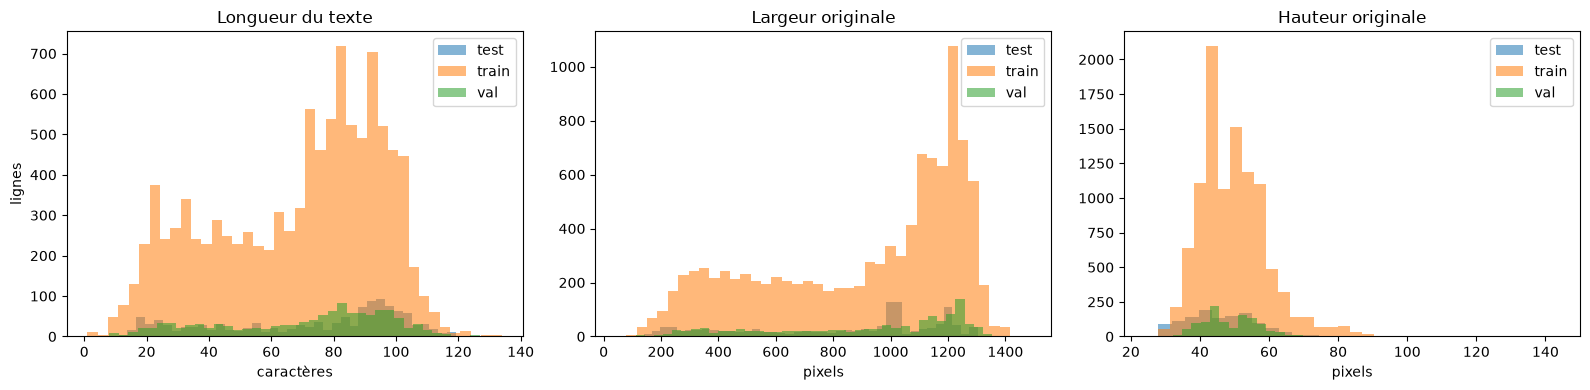

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for split, group in df.groupby('split'):
    axes[0].hist(group['text_length'], bins=40, alpha=.55, label=split)
    axes[1].hist(group['width_px'], bins=40, alpha=.55, label=split)
    axes[2].hist(group['height_px'], bins=30, alpha=.55, label=split)
axes[0].set(title='Longueur du texte', xlabel='caractères', ylabel='lignes')
axes[1].set(title='Largeur originale', xlabel='pixels')
axes[2].set(title='Hauteur originale', xlabel='pixels')
for axis in axes: axis.legend()
plt.tight_layout()
plt.show()

C:\Users\sail_\AppData\Local\Temp\ipykernel_14232\4178378320.py:9: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\sail_\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


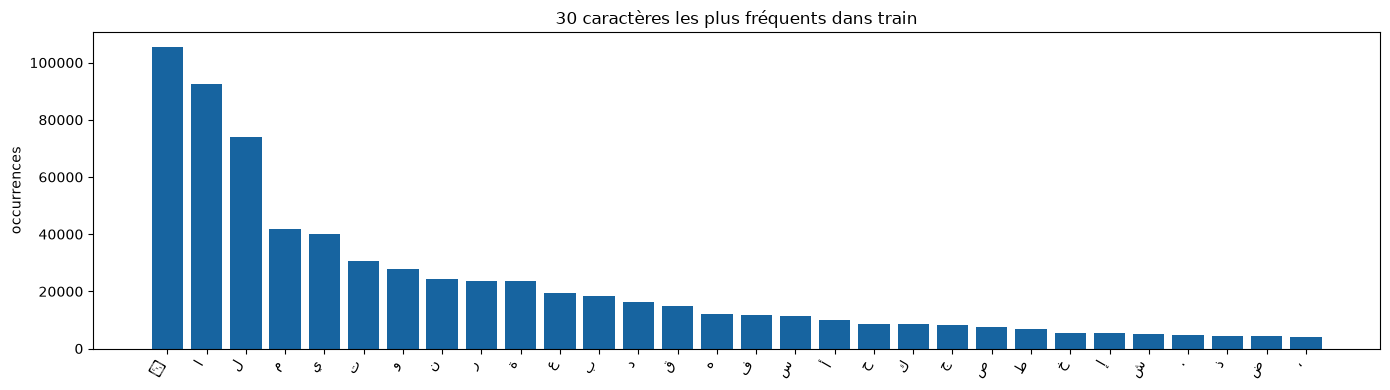

,character,count
0,,105323
1,ا,92471
2,ل,73981
3,م,41874
4,ي,39907
5,ت,30794
6,و,27805
7,ن,24245
8,ر,23582
9,ة,23519


In [5]:
chars = Counter(''.join(df.loc[df['split']=='train', 'text']))
top = pd.DataFrame(chars.most_common(30), columns=['character','count'])
top['label'] = top['character'].replace({' ': '␠', '\n': '↵'})
plt.figure(figsize=(14, 4))
plt.bar(top['label'], top['count'], color='#1764a0')
plt.title('30 caractères les plus fréquents dans train')
plt.ylabel('occurrences')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()
top[['character','count']]

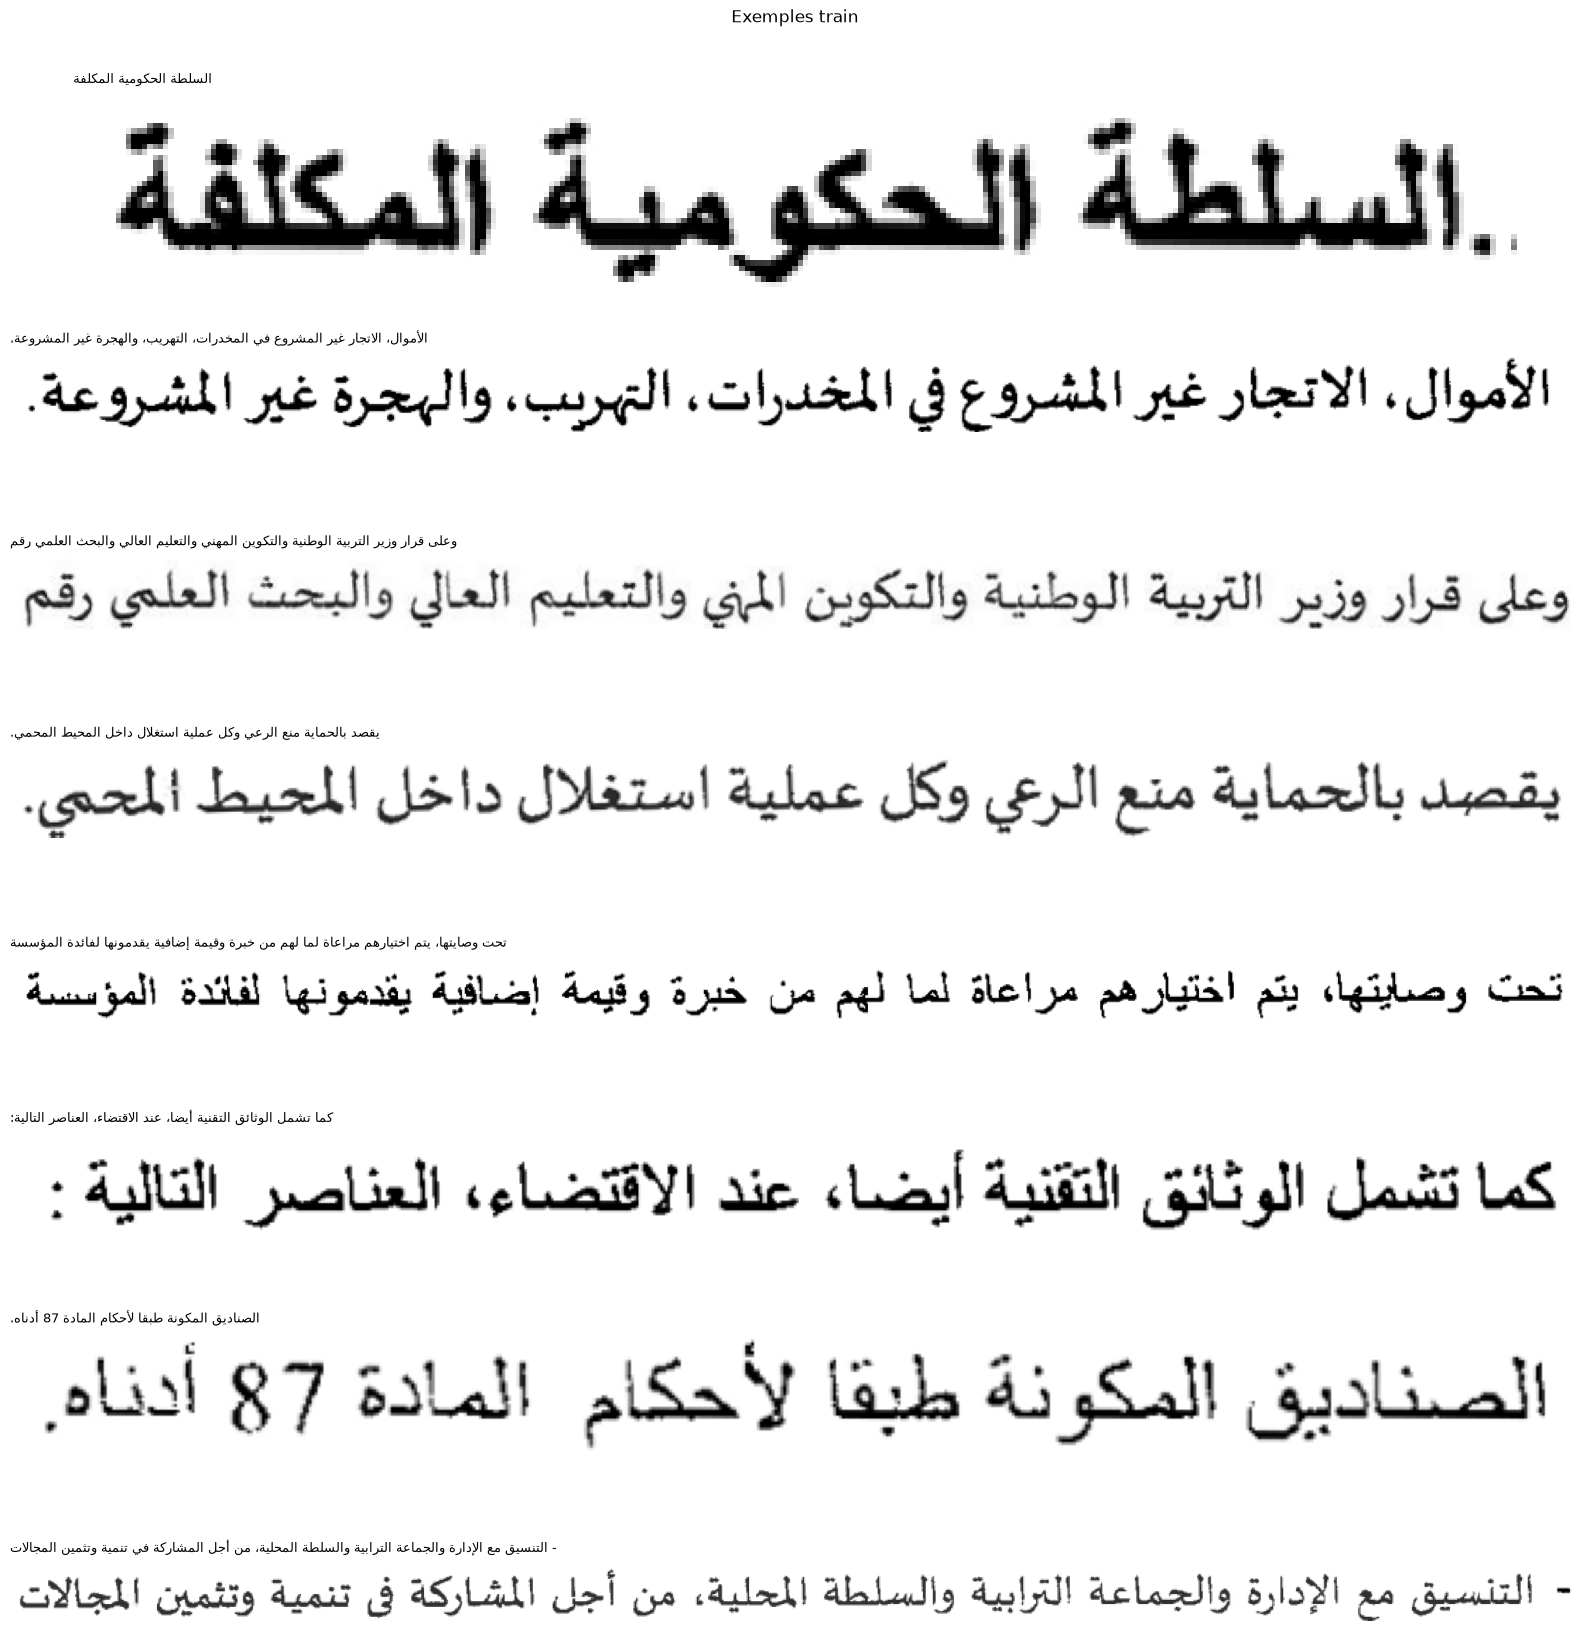

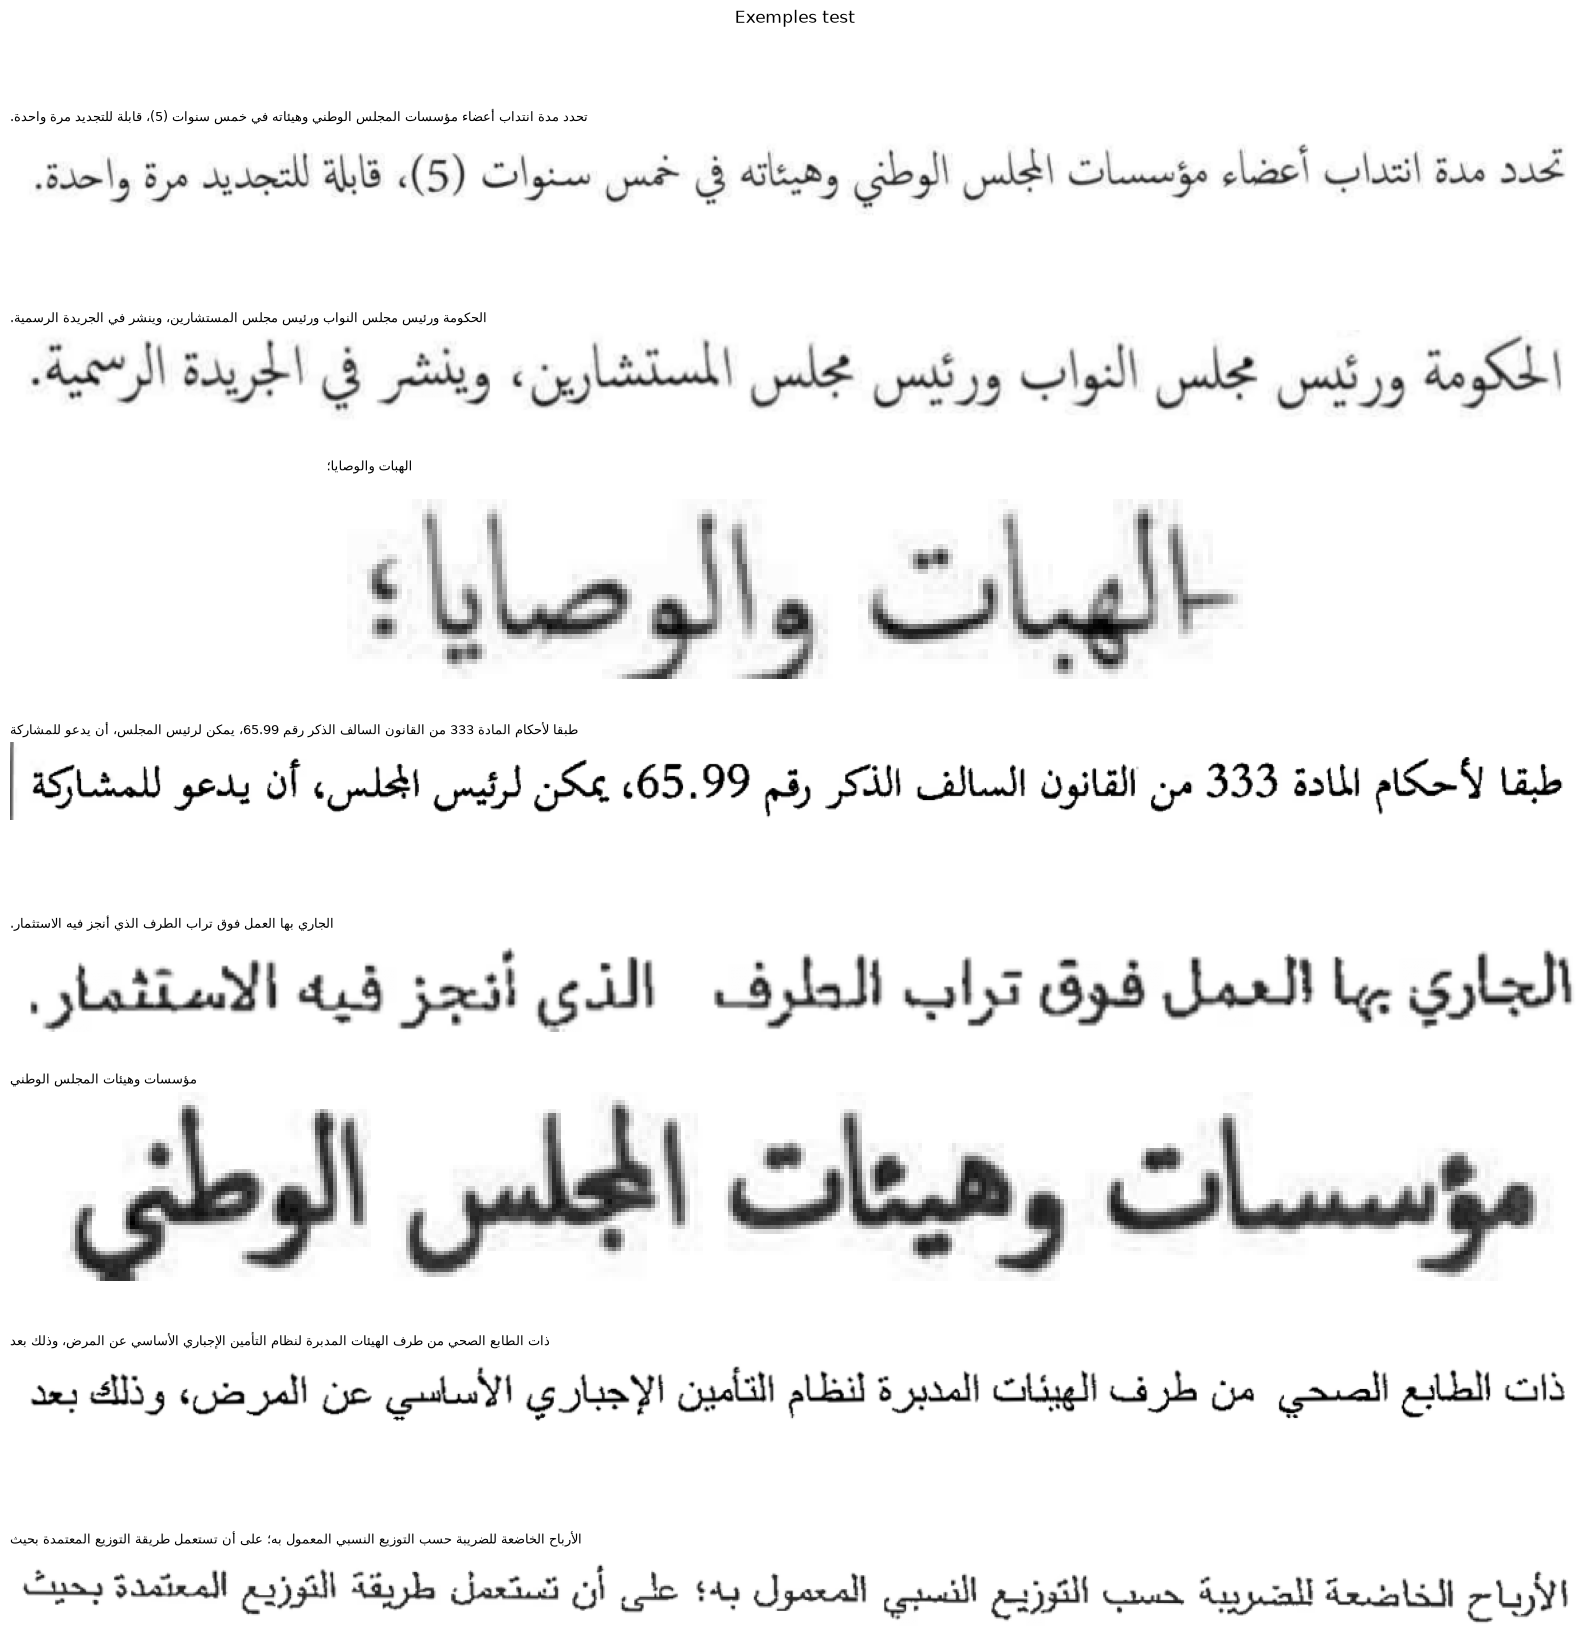

In [6]:
def show_examples(split, n=8, seed=42):
    sample = df[df['split'] == split].sample(min(n, (df['split'] == split).sum()), random_state=seed)
    fig, axes = plt.subplots(len(sample), 1, figsize=(16, max(2, 2.1*len(sample))))
    axes = np.atleast_1d(axes)
    for axis, (_, row) in zip(axes, sample.iterrows()):
        with Image.open(row['image']) as image:
            axis.imshow(image.convert('L'), cmap='gray')
        axis.set_title(row['text'][:180], loc='left', fontsize=9)
        axis.axis('off')
    fig.suptitle(f'Exemples {split}', y=1.01)
    plt.tight_layout()
    plt.show()

show_examples('train')
show_examples('test')